<a href="https://colab.research.google.com/github/Reben80/Data110-Fall2026-CRN21802/blob/main/week-11/figure-design.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Figure design

**Worksheet · Data 110 · Fall 2026 · Week 11**
Rebin Muhammad

This is the homework for the lecture. Do it after class. Run each cell with **Shift+Enter**, from the top.

Under each exercise there is an empty cell. Write your solution in that cell, then run it. This file does not contain the answers.

## How to open this in Google Colab

Click the **Open in Colab** badge at the top. The temperature table loads from this GitHub folder, so you do not upload a CSV.


## Setup

pandas holds the tables. matplotlib draws the charts. `KernelDensity` turns a list of temperatures into a density curve. You used it in Week 6.


In [1]:
import matplotlib.pyplot as plt  # pyplot draws the plots. We call it plt.
import numpy as np               # numpy does the math. We call it np.
import pandas as pd              # pandas holds tables. We call it pd.
from sklearn.neighbors import KernelDensity  # KernelDensity computes a density curve.

# The spines are the four lines that make the frame.
# False hides the top line and the right line.
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False


## The temperature table

One row is one day in Lincoln, Nebraska, in 2016.

- `month_long` is the full month name, `January` through `December`.
- `mean_temp` is that day's average temperature, in degrees Fahrenheit.

`read_csv` turns the file into a table. `head()` shows the first five rows.


In [2]:
temps = pd.read_csv("https://raw.githubusercontent.com/Reben80/Data110-Fall2026-CRN21802/main/week-11/lincoln_temps.csv")
print(len(temps), "days")
temps.head()


366 days


,date,month,month_long,mean_temp
0,2016-01-01,Jan,January,24
1,2016-01-02,Jan,January,23
2,2016-01-03,Jan,January,23
3,2016-01-04,Jan,January,17
4,2016-01-05,Jan,January,29


## A density for one month

`density` is the same idea as Week 6. `bandwidth=3.4` is the width of each day's bell, in degrees.


In [3]:
def density(values, grid, bandwidth=3.4):
    model = KernelDensity(kernel="gaussian", bandwidth=bandwidth)
    model.fit(np.asarray(values, dtype=float).reshape(-1, 1))
    return np.exp(model.score_samples(np.asarray(grid, dtype=float).reshape(-1, 1)))


NAMES = ["January", "February", "March", "April", "May", "June",
         "July", "August", "September", "October", "November", "December"]
GRID = np.linspace(-20, 105, 400)


## A draft ridgeline

This function draws one density per month. January is the top row. It is a **draft**: gray fill, no axis title, and the faint tails are still there.

You will change copies of this idea in the exercises. Do not edit this cell.


In [4]:
def draft_ridges(frame):
    """A first look. Not a finished figure."""
    curves = []
    for name in NAMES:
        values = frame.loc[frame["month_long"] == name, "mean_temp"].to_numpy()
        curves.append(density(values, GRID))
    peak = max(curve.max() for curve in curves)
    fig, ax = plt.subplots(figsize=(8, 5.2))
    for i, curve in enumerate(curves):
        baseline = 11 - i
        height = curve / peak * 1.35
        ax.fill_between(GRID, baseline, baseline + height, color="#c8c8c8")
        ax.plot(GRID, baseline + height, color="#333333", linewidth=1)
    ax.set_yticks(range(12))
    ax.set_yticklabels(list(reversed(NAMES)))
    ax.set_xlim(-15, 100)
    return ax


## 1. Draw the draft

**Exercise.** Call `draft_ridges(temps)`.

This is the starting picture from the lecture. A default plot is a first look.

### Your solution

Write your code in the next cell, then run it.


<Axes: >

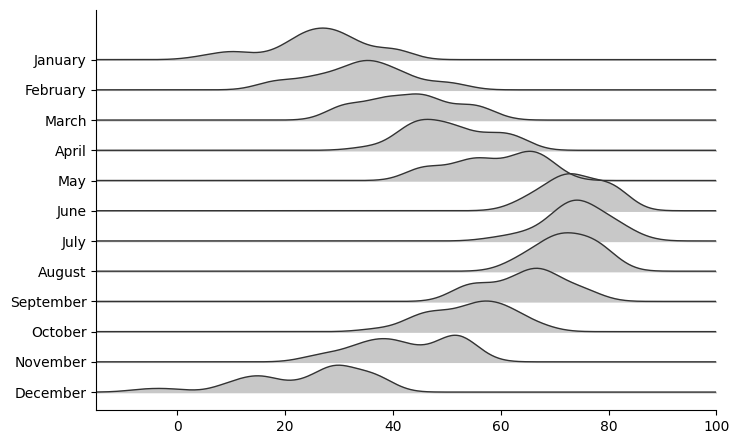

In [5]:
# Write your solution here.

draft_ridges(temps)


## 2. Cut the tails

A density never quite hits zero. Those long tails are not real days. Drop values below 1% of that month's peak.

**Exercise.** Copy the draft. After you compute `curve`, add:

```python
curve = np.where(curve < 0.01 * curve.max(), 0, curve)
```

Use overlap `2.6` instead of `1.35`, so the months sit closer together.

### Your solution

Write your code in the next cell, then run it.


<Axes: >

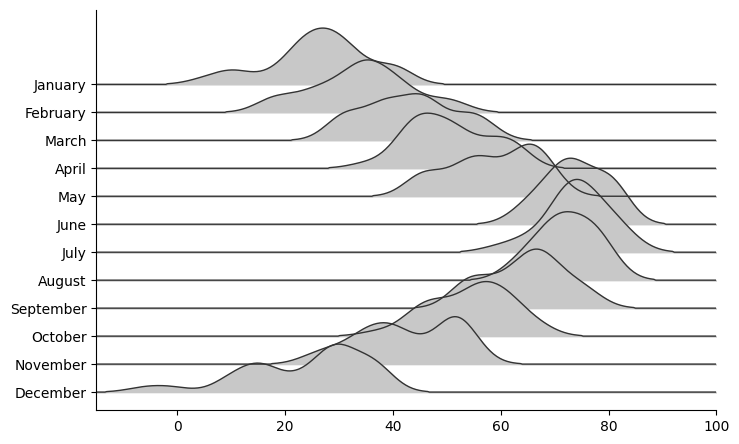

In [9]:
# Write your solution here.

def draft_ridges(frame):
    """A first look. Not a finished figure."""
    curves = []
    for name in NAMES:
        values = frame.loc[frame["month_long"] == name, "mean_temp"].to_numpy()
        curve = density(values, GRID)
        curve = np.where(curve < 0.01 * curve.max(), 0, curve)
        curves.append(curve)
    peak = max(curve.max() for curve in curves)
    fig, ax = plt.subplots(figsize=(8, 5.2))
    for i, curve in enumerate(curves):
        baseline = 11 - i
        height = curve / peak * 2.6
        ax.fill_between(GRID, baseline, baseline + height, color="#c8c8c8")
        ax.plot(GRID, baseline + height, color="#333333", linewidth=1)
    ax.set_yticks(range(12))
    ax.set_yticklabels(list(reversed(NAMES)))
    ax.set_xlim(-15, 100)
    return ax


draft_ridges(temps)









## 3. Label the axis

**Exercise.** Start from your ridgeline in exercise 2. Add:

```python
ax.set_xlabel("mean temperature (°F)")
```

The y axis is already a list of months, so it needs no title. The x axis is a number, so it needs units.

### Your solution

Write your code in the next cell, then run it.


<Axes: xlabel='mean temperature (°F)'>

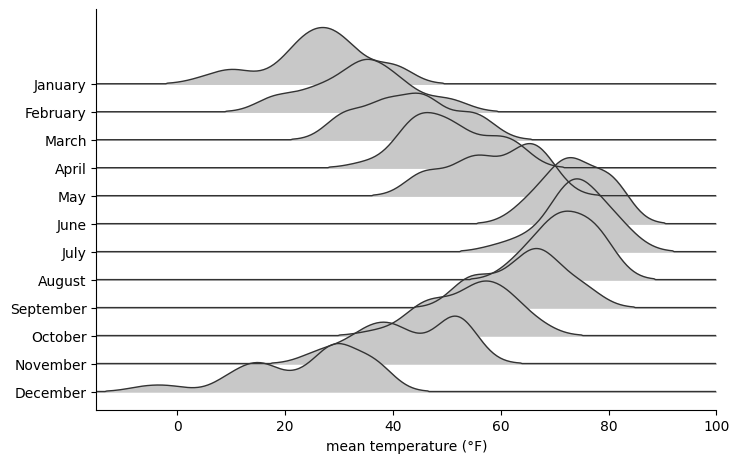

In [10]:
# Write your solution here.

def draft_ridges(frame):
    """A first look. Not a finished figure."""
    curves = []
    for name in NAMES:
        values = frame.loc[frame["month_long"] == name, "mean_temp"].to_numpy()
        curve = density(values, GRID)
        curve = np.where(curve < 0.01 * curve.max(), 0, curve)
        curves.append(curve)
    peak = max(curve.max() for curve in curves)
    fig, ax = plt.subplots(figsize=(8, 5.2))
    for i, curve in enumerate(curves):
        baseline = 11 - i
        height = curve / peak * 2.6
        ax.fill_between(GRID, baseline, baseline + height, color="#c8c8c8")
        ax.plot(GRID, baseline + height, color="#333333", linewidth=1)
    ax.set_yticks(range(12))
    ax.set_yticklabels(list(reversed(NAMES)))
    ax.set_xlabel("mean temperature (°F)")
    ax.set_xlim(-15, 100)
    return ax


draft_ridges(temps)

## 4. Choose a fill, then outline in white

**Exercise.** Start from exercise 3. Change the fill to `"#7DCCFF"` and the outline to `"white"`.

Blue is a decision. White outlines separate overlapping months. Black outlines shout.

### Your solution

Write your code in the next cell, then run it.


<Axes: xlabel='mean temperature (°F)'>

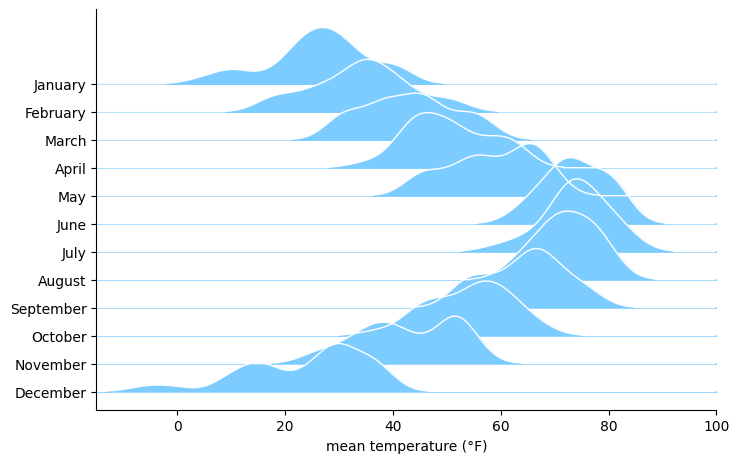

In [13]:
# Write your solution here.

def draft_ridges(frame):
    """A first look. Not a finished figure."""
    curves = []
    for name in NAMES:
        values = frame.loc[frame["month_long"] == name, "mean_temp"].to_numpy()
        curve = density(values, GRID)
        curve = np.where(curve < 0.01 * curve.max(), 0, curve)
        curves.append(curve)
    peak = max(curve.max() for curve in curves)
    fig, ax = plt.subplots(figsize=(8, 5.2))
    for i, curve in enumerate(curves):
        baseline = 11 - i
        height = curve / peak * 2.6
        ax.fill_between(GRID, baseline, baseline + height, color="#7DCCFF")
        ax.plot(GRID, baseline + height, color="white", linewidth=1)
    ax.set_yticks(range(12))
    ax.set_yticklabels(list(reversed(NAMES)))
    ax.set_xlabel("mean temperature (°F)")
    ax.set_xlim(-15, 100)
    return ax


draft_ridges(temps)

## 5. A starting style

**Exercise.** Load the penguins table, then draw flipper length against body mass. Color the points by species. Use a Matplotlib style first.

```python
plt.style.use("seaborn-v0_8-whitegrid")
```

Label the axes with units: `Flipper length (mm)` and `Body mass (g)`.

`sns.load_dataset("penguins")` downloads a small table. Colab already has seaborn.

### Your solution

Write your code in the next cell, then run it.


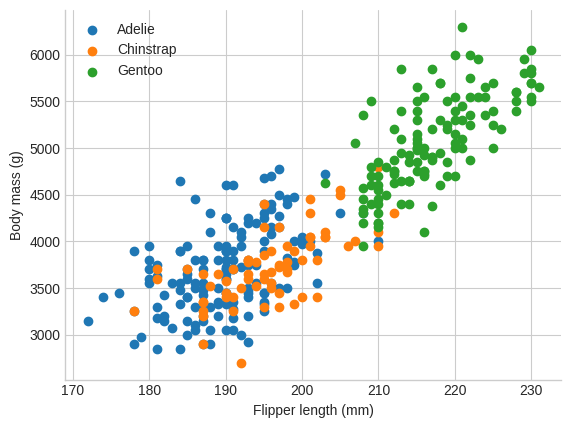

In [29]:
# Write your solution here.
import seaborn as sns

plt.style.use("seaborn-v0_8-whitegrid")
penguins = sns.load_dataset("penguins")

fig, ax = plt.subplots()

adelie = penguins.loc[penguins["species"] == "Adelie"]
chinstrap = penguins.loc[penguins["species"] == "Chinstrap"]
gentoo = penguins.loc[penguins["species"] == "Gentoo"]

ax.scatter(adelie["flipper_length_mm"], adelie['body_mass_g'], label = "Adelie")
ax.scatter(chinstrap["flipper_length_mm"], chinstrap['body_mass_g'], label = "Chinstrap")
ax.scatter(gentoo["flipper_length_mm"], gentoo['body_mass_g'], label = "Gentoo")
ax.set_xlabel("Flipper length (mm)")
ax.set_ylabel("Body mass (g)")

ax.legend()
plt.show()


## 6. Rewrite the caption

This caption is not a title:

> This figure shows a ridgeline plot of the data.

**Exercise.** In the next cell, `print` a better caption. It should start with a title, make a short claim, and name the file.

Do not begin with “This figure shows.”

### Your solution

Write your code in the next cell, then run it.


In [ ]:
# Write your solution here.
print("Monthly Temperature Distributions: Distribution generally increases in temperature from January to July, and decreases afterward. Data Source: lincoln_temps.csv")

## What to keep

- A default plot is a draft.
- Design is a sequence: shape, labels, color.
- Write units on a number axis. Skip a title when the labels are already words.
- One title. In a report, it is the first sentence of the caption.
- `plt.style.use` picks a starting look. You still edit.

Upload your notebook when you are done, if the instructor asks for it on Blackboard or Teams.
